In [4]:
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("tokenizers/shared-tokenizer")

import json
from src.utils.modules import Transformer
with open(f"models/model.json") as f:
    config = json.load(f)
model = Transformer(config)
checkpoint = torch.load("models/model.pth", map_location="cpu")
model.load_state_dict(checkpoint["model"])
model.eval()

embeddings = model.shared_embeddings.token_embeddings.weight

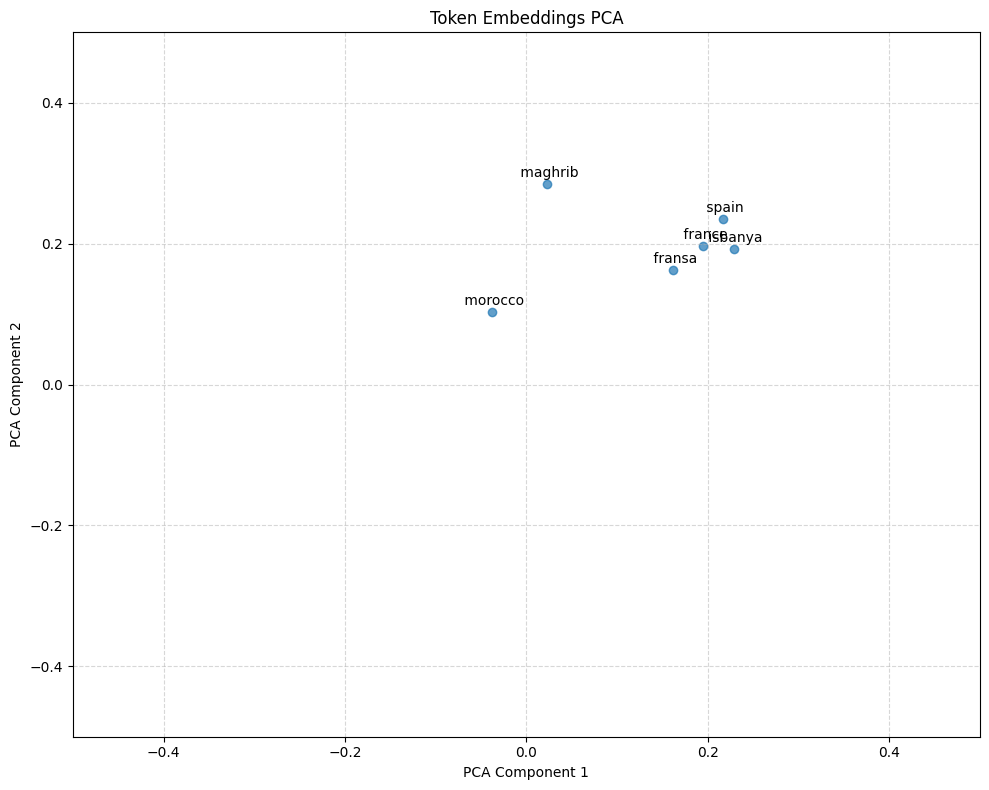

In [84]:
def compute_pca_on_all(embedding_matrix):
    """Reduce embedding matrix to 2D using PCA."""
    pca = PCA(n_components=2)
    return pca.fit_transform(embedding_matrix.detach().cpu().numpy())

def plot_tokens_pca_on_all(tokens, reduced, title="Token Embeddings PCA"):
    """
    Plot tokens in 2D space using PCA on their embeddings.

    Args:
        tokens (list): List of tokens to visualize.
        title (str): Title for the plot.
    """
    # Tokenize and get indices
    token_indices = []
    for token in tokens:
        # Handle tokenization (adjust based on your tokenizer's behavior)
        encoded = tokenizer.encode(token, add_special_tokens=False)
        if not encoded:
            print(f"Warning: Token '{token}' not found in vocabulary.")
            continue
        token_indices.append(encoded[0])  # Take the first token ID

    if not token_indices:
        print("No valid tokens to plot.")
        return
    """
    # Get embeddings for tokens
    vecs = embeddings[token_indices].clone().detach().numpy()

    # Compute PCA
    reduced = compute_pca(vecs)
    """
    outputs = reduced[token_indices]

    # Plot
    plt.figure(figsize=(10, 8))
    plt.scatter(outputs[:, 0], outputs[:, 1], alpha=0.7)

    # Annotate tokens
    for i, token in enumerate(tokens):
        plt.annotate(
            token,
            (outputs[i, 0], outputs[i, 1]),
            textcoords="offset points",
            xytext=(0, 5),
            ha="center",
        )

    # Add labels and title
    plt.xlabel("PCA Component 1")
    plt.xlim([-0.5, 0.5])
    plt.ylim([-0.5, 0.5])
    plt.ylabel("PCA Component 2")
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# Example usage
plot_tokens_pca_on_all([" maghrib", " morocco", " fransa", " isbanya", " france", " spain"], reduced)

In [5]:
import numpy as np
def compute_pca(embedding_matrix):
    """Reduce embedding matrix to 2D using PCA."""
    pca = PCA(n_components=2)
    return pca.fit_transform(embedding_matrix)

def plot_tokens_pca(token_groups, categories, title="Theme-based clustering"):
    """
    Plot tokens in 2D space using PCA on their embeddings.
    All tokens are projected together, but colored by their group.

    Args:
        token_groups (list of lists): List of token lists to visualize.
        title (str): Title for the plot.
    """
    # Collect all tokens and their group indices
    all_tokens = []
    all_group_indices = []
    for group_idx, tokens in enumerate(token_groups):
        for token in tokens:
            all_tokens.append(token)
            all_group_indices.append(group_idx)

    # Tokenize and get indices for all tokens
    token_indices = []
    for token in all_tokens:
        encoded = tokenizer.encode(token, add_special_tokens=False)
        if not encoded:
            print(f"Warning: Token '{token}' not found in vocabulary.")
            continue
        token_indices.append(encoded[0])

    if not token_indices:
        print("No valid tokens to plot.")
        return

    # Get embeddings for all tokens
    vecs = embeddings[token_indices].clone().detach().numpy()

    # Compute PCA on all embeddings together
    reduced = compute_pca(vecs)

    # Assign colors to each group
    unique_groups = np.unique(all_group_indices)

    # Plot
    plt.figure(figsize=(10, 8))
    for group_idx in unique_groups:
        mask = np.array(all_group_indices) == group_idx
        plt.scatter(
            reduced[mask, 0],
            reduced[mask, 1],
            label=f"{categories[group_idx]}"
        )
        # Annotate tokens for this group
        for i, token in enumerate(all_tokens):
            if all_group_indices[i] == group_idx:
                plt.annotate(
                    token,
                    (reduced[i, 0], reduced[i, 1]),
                    textcoords="offset points",
                    xytext=(0, 5),
                    ha="center"
                )

    # Add labels, title, and legend
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


    # Add labels, title, and legend
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
reduced = compute_pca_on_all(embeddings)    

In [174]:
tokenizer.encode(" tmanya")[1:-1] # cat:7030, dog:12705, france:12116, spain:7368

[31775]

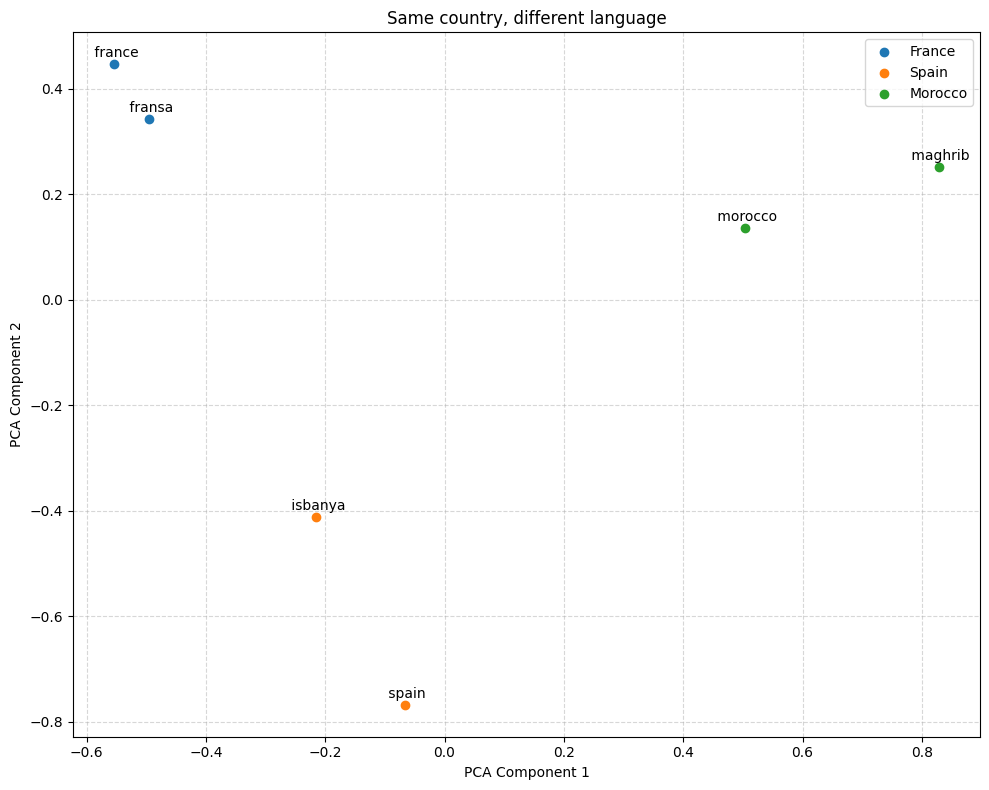

C:\Users\ilias\AppData\Local\Temp\ipykernel_11136\2110051073.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


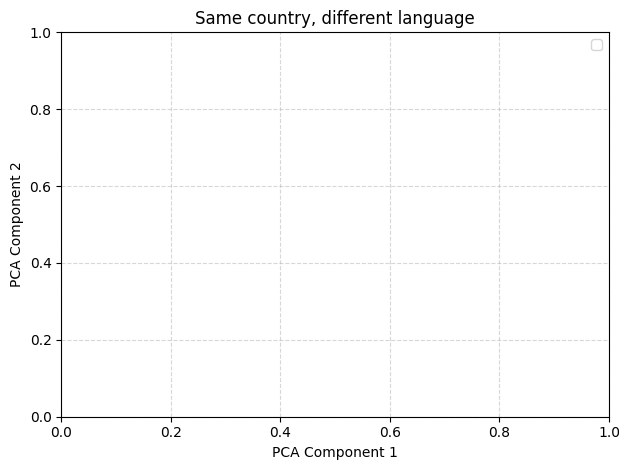

In [7]:
france = [" fransa", " france"]
spain = [" spain", " isbanya"]
morocco_ = [" morocco", " maghrib"]
category_names = ["France", "Spain", "Morocco"]
plot_tokens_pca([france, spain, morocco_], category_names, title="Same country, different language")

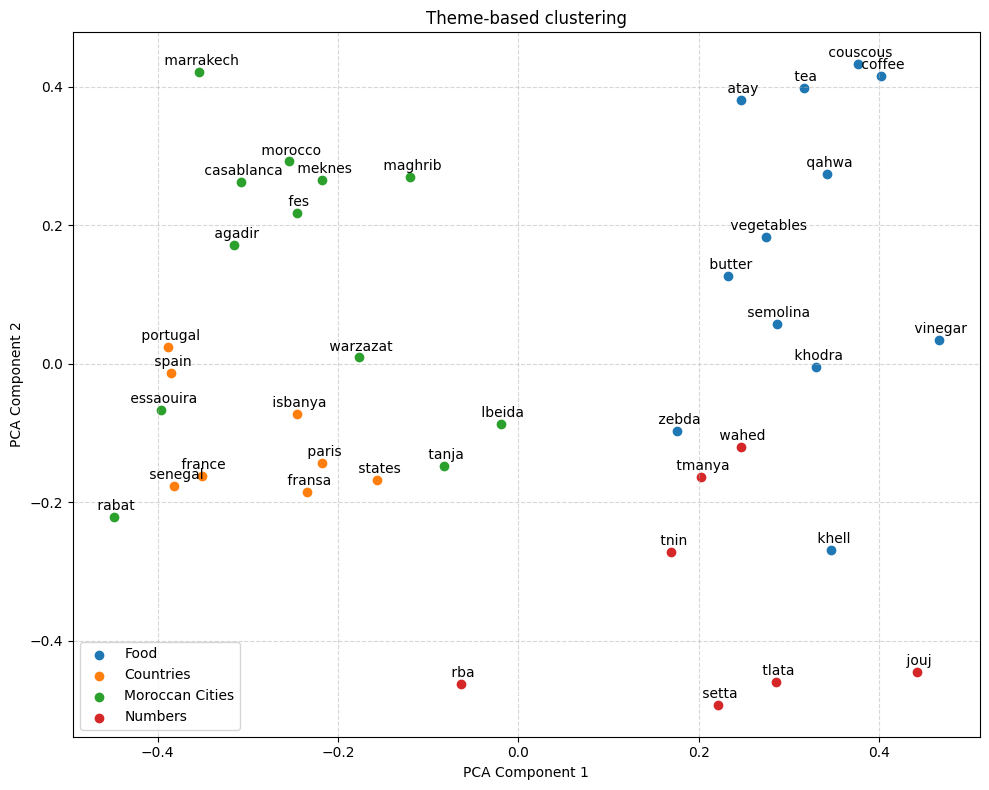

C:\Users\ilias\AppData\Local\Temp\ipykernel_17600\2110051073.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


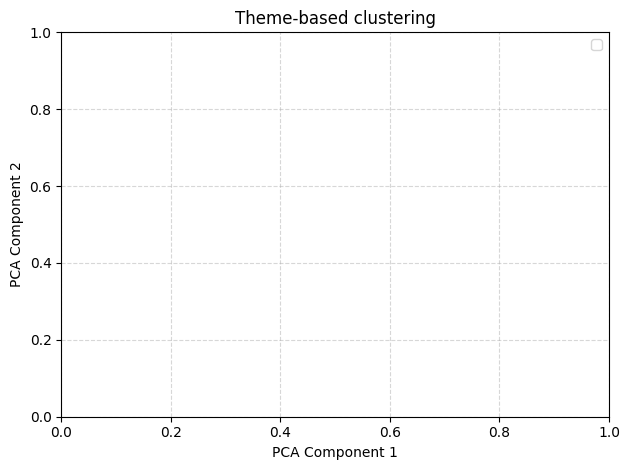

In [8]:
food = [" zebda", " butter", " qahwa", " coffee", " atay", " tea", " khell", " vinegar", " khodra", " vegetables", " semolina", " couscous"]
countries = [" fransa", " isbanya", " france", " spain", " portugal", " paris", " states", " senegal"]
morocco = [" maghrib", " morocco", " tanja", " lbeida", " marrakech", " essaouira", " rabat", " warzazat", " casablanca", " fes", " meknes", " agadir"]
numbers = [" wahed", " jouj", " tlata", " rba", " setta", " tnin", " tmanya"]
all = [food, countries, morocco, numbers]
category_names = ["Food", "Countries", "Moroccan Cities", "Numbers"]

plot_tokens_pca(all, category_names)